# Лабораторная работа № 3. Описательная статистика

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Получить и интерпретировать описательные статистики данных о стекле: центральные меры, разброс, квантили, выбросы, корреляции.

## 1. Теоретическая часть

**1. Что такое описательная статистика и её цель?** Это набор методов, которые кратко описывают данные числами и графиками: где находится центр, насколько велик разброс, какова форма распределения, есть ли выбросы и связи между признаками. Цель — понять структуру данных до построения моделей.

**2. Отличия показателей.**
- *Среднее арифметическое* — сумма значений, делённая на их число; чувствительно к выбросам.
- *Медиана* — значение, делящее упорядоченную выборку пополам; устойчива к выбросам.
- *Минимум и максимум* — крайние значения, задают диапазон; показывают границы данных, но не их центр.

**3. Задачи `describe()`** — одним вызовом выдаёт count, mean, std, min, 25 %, 50 %, 75 %, max для числовых столбцов (для категориальных — count, unique, top, freq): быстрая сводка и проверка полноты данных.

**4. Квантили** — значения, ниже которых лежит заданная доля наблюдений (квартили — 25/50/75 %). Показывают форму распределения: симметрию, «тяжёлые хвосты», позволяют вычислять IQR и обнаруживать выбросы.

**5. Разброс данных** — степень отклонения значений от центра. Описывается размахом (max − min), дисперсией, стандартным отклонением, межквартильным размахом (IQR), коэффициентом вариации.

**6. Признаки выбросов:** большая разница между средним и медианой; значения за пределами [Q1 − 1.5·IQR; Q3 + 1.5·IQR] или дальше 3σ от среднего; max/min, сильно отстоящие от 75 %/25 % квантилей; большая асимметрия и эксцесс.

## 2. Практическая часть

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

In [ ]:
print("Первые 5 строк:"); display(df.head())
print("Размерность:", df.shape)
display(df.dtypes.to_frame("dtype").T)
print("Числовые:", df.select_dtypes("number").columns.tolist())
print("Категориальные: нет object-столбцов; Type - код сорта (категориальная по смыслу)")

Первые 5 строк:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Размерность: (214, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


Числовые: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
Категориальные: нет object-столбцов; Type - код сорта (категориальная по смыслу)


### 2.1. Основные статистические показатели

In [ ]:
display(df[FEATURES].describe().T.round(3))#универссальная сводка

,count,mean,std,min,25%,50%,75%,max
RI,214.0,1.518,0.003,1.511,1.517,1.518,1.519,1.534
Na,214.0,13.408,0.817,10.730,12.908,13.300,13.825,17.380
Mg,214.0,2.685,1.442,0.000,2.115,3.480,3.600,4.490
Al,214.0,1.445,0.499,0.290,1.190,1.360,1.630,3.500
Si,214.0,72.651,0.775,69.810,72.280,72.790,73.088,75.410
K,214.0,0.497,0.652,0.000,0.122,0.555,0.610,6.210
Ca,214.0,8.957,1.423,5.430,8.240,8.600,9.172,16.190
Ba,214.0,0.175,0.497,0.000,0.000,0.000,0.000,3.150
Fe,214.0,0.057,0.097,0.000,0.000,0.000,0.100,0.510


In [2]:
central = pd.DataFrame({"mean": df[FEATURES].mean(), "median": df[FEATURES].median(),#Детальный разбор центра и разброса
                        "mode": df[FEATURES].mode().iloc[0]})
display(central.round(3))
spread = pd.DataFrame({"std": df[FEATURES].std(), "var": df[FEATURES].var()})#mean and median - тест на ассиметрию(std-стандартное отклонение, дисперсия - var)
display(spread.round(4))

,mean,median,mode
RI,1.518,1.518,1.516
Na,13.408,13.300,13.000
Mg,2.685,3.480,0.000
Al,1.445,1.360,1.540
Si,72.651,72.790,72.860
K,0.497,0.555,0.000
Ca,8.957,8.600,8.030
Ba,0.175,0.000,0.000
Fe,0.057,0.000,0.000


,std,var
RI,0.0030,0.0000
Na,0.8166,0.6668
Mg,1.4424,2.0805
Al,0.4993,0.2493
Si,0.7745,0.5999
K,0.6522,0.4254
Ca,1.4232,2.0254
Ba,0.4972,0.2472
Fe,0.0974,0.0095


### 2.2. Квантили и межквартильный размах

In [3]:
q = df[FEATURES].quantile([0.25, 0.5, 0.75]).T #Расчет квантилей и IQR
q.columns = ["Q1 (25%)", "медиана (50%)", "Q3 (75%)"]
q["IQR"] = q["Q3 (75%)"] - q["Q1 (25%)"]
display(q.round(3))

,Q1 (25%),медиана (50%),Q3 (75%),IQR
RI,1.517,1.518,1.519,0.003
Na,12.908,13.300,13.825,0.917
Mg,2.115,3.480,3.600,1.485
Al,1.190,1.360,1.630,0.440
Si,72.280,72.790,73.088,0.808
K,0.122,0.555,0.610,0.488
Ca,8.240,8.600,9.172,0.932
Ba,0.000,0.000,0.000,0.000
Fe,0.000,0.000,0.100,0.100


In [4]:
vc = df["Type"].map(TYPE_NAMES).value_counts()#Анализ целевой переменной (баланс классов)
display(pd.DataFrame({"частота": vc, "доля, %": (vc / len(df) * 100).round(1)}))
print("Самый частый сорт:", vc.idxmax(), vc.max(), "| самый редкий:", vc.idxmin(), vc.min())
print("Распределение неравномерное: отношение max/min =", round(vc.max() / vc.min(), 1))

,частота,"доля, %"
Type,,
окна зданий (non-float),76,35.5
окна зданий (float),70,32.7
фары,29,13.6
окна авто (float),17,7.9
контейнеры,13,6.1
посуда,9,4.2


Самый частый сорт: окна зданий (non-float) 76 | самый редкий: посуда 9
Распределение неравномерное: отношение max/min = 8.4


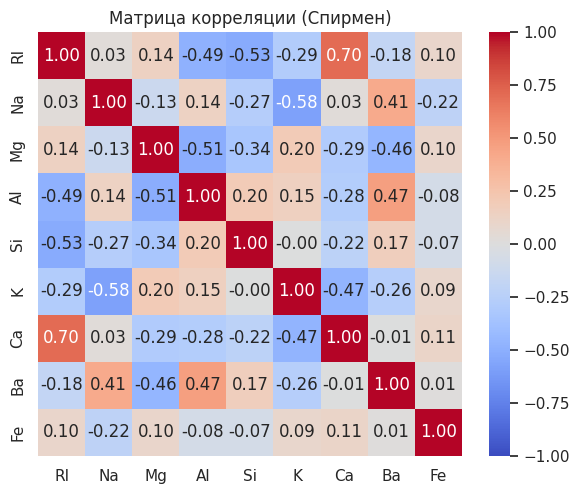

,,r
RI,Ca,0.704
Na,K,-0.585
RI,Si,-0.526
Mg,Al,-0.512
RI,Al,-0.492
Al,Ba,0.475
K,Ca,-0.473
Mg,Ba,-0.456
Na,Ba,0.411


In [5]:
#Корреляция Спирмена и тепловая карта
corr = df[FEATURES].corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Матрица корреляции (Спирмен)"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
strong = pairs[pairs.abs() >= 0.4].sort_values(key=abs, ascending=False)# Фильтрация только сильных связей (по модулю >= 0.4)
display(strong.round(3).to_frame("r"))

**Результат.** По Спирмену сильнее всего связаны RI и Ca (r ≈ 0.70: чем больше CaO, тем выше показатель преломления), Na и K (≈ −0.59), RI и Si (≈ −0.53), Mg и Al (≈ −0.51), RI и Al (≈ −0.49), а также Al и Ba (≈ 0.48). Остальные пары слабо зависимы.

### 2.3. Интерпретация статистических характеристик

In [6]:
rows = [] #Автоматический расчет границ выбросов и асимметрии для всех признаков
for f in FEATURES:
    s = df[f]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr #Границы по правилу IQR
    m, sd = s.mean(), s.std()
    out_iqr = ((s < lo) | (s > hi)).sum()# Считаем, сколько значений вышло за границы IQR
    out_3s = ((s < m - 3 * sd) | (s > m + 3 * sd)).sum()# Считаем выбросы по правилу 3-х сигм
    rows.append([f, round(lo, 3), round(hi, 3), out_iqr, round(m - 3 * sd, 3), round(m + 3 * sd, 3), out_3s, round(s.skew(), 2)])
typ = pd.DataFrame(rows, columns=["признак", "нижняя (IQR)", "верхняя (IQR)", "выбросов IQR", "m-3σ", "m+3σ", "выбросов 3σ", "асимметрия"]).set_index("признак")
display(typ)
print("Всего значений вне IQR-диапазона:", typ["выбросов IQR"].sum(), "| вне 3σ:", typ["выбросов 3σ"].sum())

,нижняя (IQR),верхняя (IQR),выбросов IQR,m-3σ,m+3σ,выбросов 3σ,асимметрия
признак,,,,,,,
RI,1.513,1.523,17,1.509,1.527,3,1.63
Na,11.531,15.201,7,10.958,15.858,2,0.45
Mg,-0.113,5.828,0,-1.643,7.012,0,-1.15
Al,0.530,2.290,18,-0.053,2.943,3,0.91
Si,71.069,74.299,12,70.327,74.975,6,-0.73
K,-0.609,1.341,7,-1.460,2.454,3,6.55
Ca,6.841,10.571,26,4.688,13.226,7,2.05
Ba,0.000,0.000,38,-1.317,1.667,6,3.42
Fe,-0.150,0.250,12,-0.235,0.349,3,1.75


Всего значений вне IQR-диапазона: 137 | вне 3σ: 33


In [7]:
# какие образцы дают выбросы по Ba, K и Fe и к каким сортам они относятся
for f in ["Ba", "K", "Fe"]:
    q1, q3 = df[f].quantile([.25, .75]); iqr = q3 - q1
    o = df[(df[f] > q3 + 1.5 * iqr)]
    print(f, "- выбросы по сортам:", o["Type"].value_counts().sort_index().to_dict())

Ba - выбросы по сортам: {1: 3, 2: 6, 3: 1, 5: 2, 7: 26}
K - выбросы по сортам: {5: 3, 7: 4}
Fe - выбросы по сортам: {1: 3, 2: 6, 3: 1, 5: 2}


In [8]:
# корреляция Пирсона с целевой переменной и между признаками
print("Корреляция признаков с Type (Пирсон):")
display(df.corr(method="pearson")["Type"].drop("Type").round(3).sort_values(key=abs, ascending=False).to_frame("r"))
p = df[FEATURES].corr(method="pearson"); pp = p.where(np.triu(np.ones(p.shape, dtype=bool), 1)).stack()
print("Самые сильные пары (Пирсон):"); display(pp.reindex(pp.abs().sort_values(ascending=False).index).head(5).round(3).to_frame("r"))

Корреляция признаков с Type (Пирсон):


,r
Mg,-0.745
Al,0.599
Ba,0.575
Na,0.503
Fe,-0.188
RI,-0.164
Si,0.152
K,-0.010
Ca,0.001


Самые сильные пары (Пирсон):


r
RI Ca  0.810
   Si -0.542
Mg Ba -0.492
   Al -0.482
Al Ba  0.479

### Вывод

Набор данных содержит 214 образцов и 9 числовых признаков; пропусков нет, категориальной является только целевая переменная Type с шестью сортами стекла, причём классы заметно несбалансированы (сорта 1 и 2 вместе составляют около 68 % выборки). Наиболее информативными характеристиками оказались стандартное отклонение вместе со средним (через коэффициент вариации), квартили с IQR и коэффициент асимметрии: они сразу показывают, что признаки Ba, Fe и K имеют сильно скошенные распределения с большим числом нулей, а Na, Si и Al распределены умеренно симметрично. Медиана и мода для Ba и Fe равны нулю (мода K тоже 0), тогда как среднее заметно больше — это типичный признак правостороннего скоса и выбросов. По правилу 1.5·IQR выбросы обнаружены во всех признаках, кроме Mg (всего 137 значений), особенно много их у Ba (38), Ca (26), Al (18) и RI (17); по правилу трёх сигм их существенно меньше (33). Эти значения нельзя считать ошибками измерений: проверка показала, что 26 из 38 выбросов по Ba относятся к фарам, выбросы по K — к контейнерам и фарам, выбросы по Fe — к окнам и контейнерам, то есть они отражают реальные особенности состава и несёт информацию для классификации. Корреляционный анализ выявил сильную положительную связь RI и Ca (Пирсон 0.81, Спирмен 0.70) и отрицательные связи RI–Si, Mg–Ba и Mg–Al; с целевой переменной сильнее всего связаны Mg (отрицательно), Al, Ba и Na (положительно). Таким образом, химический состав действительно различает сорта стекла. Качество данных высокое: пропусков и физически невозможных значений нет, но один дубликат и сильная асимметрия признаков требуют очистки и масштабирования. Малые классы (посуда, контейнеры) придётся учитывать при разбиении выборок и оценке моделей.